# HW-Clustering: Segmenting Gym Members

A gym wants to divide its members into a few groups so that it can send each group a different offer. The data has 36 members and two columns: `VisitsPerMonth` (the average number of visits per month) and `AnnualSpending` (the dollars the member spent last year on membership, classes and personal training). There is **no** column that says what type of member each one is: that is what K-means clustering will discover.

**The homework has 12 multiple-choice problems.** Problems 1 to 4 are conceptual problems: no code is required. Problems 5 to 12 require brief coding: each one comes with starter code from the lecture, and you fill in the missing pieces.

**Where to get this file.** This notebook, the homework instruction file, can be downloaded from the course GitHub repository, under **Clustering**.

**Where to answer.** These 12 problems are also the 12 questions of the **HW-Clustering quiz on Canvas**, in the same order and with the same answer choices. Use this notebook to work out your answers, then enter them in the Canvas quiz; only the Canvas quiz is graded. Problems 1 to 4 are worth **5 points** each and Problems 5 to 12 are worth **10 points** each, for **100 points** in total. See Canvas for the due date.

**You must scale the inputs before you run K-means clustering, just like in the lecture.** K-means clustering uses distance, and annual spending (hundreds to thousands of dollars) has much bigger numbers than visits per month (single digits to the twenties). Use `StandardScaler`:

- call `fit_transform()` **once**, on the 36 members
- call `transform()` (not `fit_transform()`) on every new member
- fit K-means clustering on the **scaled** data, and scale every new member before you call `predict()`

Use `k = 3` (`n_clusters=3`), `random_state=42` and `n_init=10` unless a problem says otherwise.

## How to use this notebook

- Run the cells **in order**, from top to bottom (Shift+Enter runs a cell). Later cells use the variables created in earlier cells.
- **Problems 1 to 4:** read the problem and choose an answer. No code is needed.
- **Problems 5 to 12:** each one comes with starter code. Replace every `____` with your own code, then run the cell. A cell that still contains `____` stops with an error.
- Each problem ends with a "Your answer" cell. Double-click it and type A, B, C or D to keep track of your answer. When you are done, enter your answers in the HW-Clustering quiz on Canvas.
- If you change a cell, run the cells below it again. If your results look strange, restart the notebook and run all the cells again from the top.
- The code follows the lecture notebook step by step, so keep the lecture open while you work.

## Setup

Run this cell first. It is the same as in the lecture.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Print numpy arrays with 3 decimals, to keep the outputs readable.
np.set_printoptions(precision=3, suppress=True)

## The data

The next two cells create the data and show it. They are complete: just run them.

In [2]:
# Create one simple gym-member dataset.
# There is NO label column: we do not know the member types in advance.

member_df = pd.DataFrame({
    "VisitsPerMonth": [
        8, 23, 16, 6, 17, 11,
        6, 26, 15, 8, 19, 16,
        6, 20, 15, 7, 20, 13,
        7, 21, 11, 3, 21, 12,
        2, 20, 9, 4, 26, 11,
        3, 24, 8, 24, 23, 22
    ],
    "AnnualSpending": [
        910, 890, 2590, 400, 1350, 2420,
        670, 980, 3400, 850, 800, 2110,
        470, 1250, 2220, 840, 760, 2350,
        460, 1250, 3360, 660, 1080, 3000,
        850, 730, 3250, 560, 680, 2360,
        590, 960, 550, 670, 750, 1010
    ]
})

print("Number of members:", len(member_df))
member_df

Number of members: 36


,VisitsPerMonth,AnnualSpending
0,8,910
1,23,890
2,16,2590
3,6,400
4,17,1350
5,11,2420
6,6,670
7,26,980
8,15,3400
9,8,850


This is a small **hand-made dataset** created only for practicing K-means clustering.

Notice that there is **no label column**. Nobody has told us what type of member each one is.

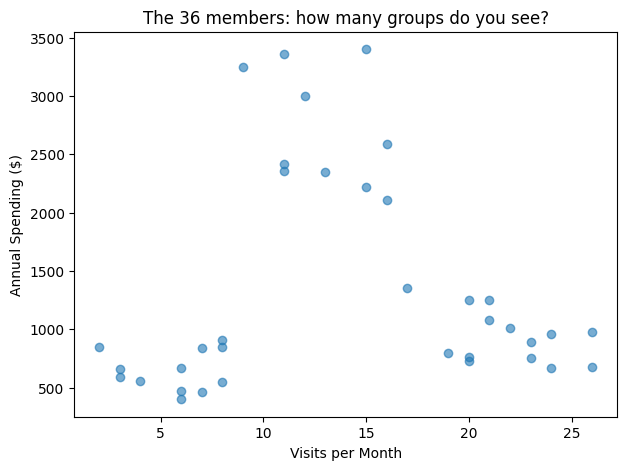

In [3]:
# Look at the data before clustering. There are no colors: we do not know the groups yet.
plt.figure(figsize=(7, 5))
plt.scatter(member_df["VisitsPerMonth"], member_df["AnnualSpending"], alpha=0.6)
plt.xlabel("Visits per Month")
plt.ylabel("Annual Spending ($)")
plt.title("The 36 members: how many groups do you see?")
plt.show()

Each dot is one member. Even without labels you can probably see a few groups. K-means clustering will find them for us.

Look at the two axes. Visits per month run from 2 to 26, while annual spending runs from 400 to 3,400 dollars. Spending has much bigger numbers, which is why we must scale the inputs.

## Part 1: Concepts (no code needed)

### Problem 1 (5 points)

KNN is a **supervised** learning method, whereas K-means clustering is an **unsupervised** learning method. Which statement explains why K-means clustering is unsupervised?

- **A.** It measures the distance between members.
- **B.** The inputs must be scaled before the model is fitted.
- **C.** The data has no label column. `fit()` receives only `X_scaled`, and the groups are discovered by the algorithm, not given in the data.
- **D.** The number of clusters `k` is chosen by the user, not learned from the data.

**Your answer to Problem 1:**

### Problem 2 (5 points)

A KNN model uses `k = 4`, and a K-means clustering model uses `k = 3`. Which statement about the two `k`'s is correct?

- **A.** In KNN, `k` is the number of nearest neighbors that vote on the label of a new point. In K-means clustering, `k` is the number of clusters to form.
- **B.** In both methods, `k` is the number of groups the data is divided into.
- **C.** In KNN, `k` is the number of clusters. In K-means clustering, `k` is the number of neighbors around each centroid.
- **D.** KNN with `k = 3` and K-means clustering with `k = 3` produce the same groups, because both methods use distance.

**Your answer to Problem 2:**

### Problem 3 (5 points)

Which statement about K-means clustering is **wrong**?

- **A.** A centroid is the center of a cluster. It is exactly the average of the members in that cluster, so it describes the typical member of that group.
- **B.** `k` is the number of clusters to form. The user chooses it before the model is fitted, for example `KMeans(n_clusters=3)`.
- **C.** No label column is required. `fit()` receives only the input columns, and the algorithm discovers the groups by itself.
- **D.** Inertia measures how tight the clusters are. A **large** inertia means that the members sit close to the centroids of their clusters.

**Your answer to Problem 3:**

### Problem 4 (5 points)

The elbow method fits K-means clustering for `k` = 1, 2, 3, ... and records the **inertia** for each `k`. Which statement is correct?

- **A.** Inertia goes down every time `k` increases, so the `k` with the smallest inertia is always the best choice.
- **B.** Inertia measures how tight the clusters are. It always goes down as `k` increases, so we look for the elbow: the `k` after which adding another cluster barely reduces the inertia.
- **C.** Inertia goes up as `k` increases, so we choose the `k` with the largest inertia.
- **D.** Inertia is the distance between the centroids. A large inertia means the clusters are well separated.

**Your answer to Problem 4:**

## Part 2: Coding

Problems 5 to 12 use the 36 members. `X` is `VisitsPerMonth` and `AnnualSpending`. There is no `y`.

Problem 9 is about three **new members** who have just joined: P (5 visits per month, \$700 a year), Q (20 visits, \$1,100) and R (7 visits, \$1,000).

Work through the problems in order. Each coding cell uses the variables created in the cells above it.

First we define `X`. This cell is complete: just run it.

In [4]:
# X = the INPUTS: the two columns we cluster on. There is no y: nobody labeled the members.
X = member_df[["VisitsPerMonth", "AnnualSpending"]]

print("X shape:", X.shape)

X shape: (36, 2)


### Problem 5 (10 points)

Scale `X` with `StandardScaler`. What do `scaler.mean_` and `scaler.scale_` show?

- **A.** Mean of each feature: `[13.972 1334.167]`, Std of each feature: `[7.274 910.151]`
- **B.** Mean of each feature: `[7.274 910.151]`, Std of each feature: `[13.972 1334.167]`
- **C.** Mean of each feature: `[0. 0.]`, Std of each feature: `[1. 1.]`
- **D.** Mean of each feature: `[50006.452 51.271]`, Std of each feature: `[21630.473 21.714]`

In [ ]:
# Lecture: Section 7, "Visualize the data and see why we need to scale"
scaler = StandardScaler()

# Learn the mean and std of each column from the 36 members, and scale them.
X_scaled = scaler.____(X)

# The scaler remembers what it learned:
print("Mean of each feature:", scaler.mean_)
print("Std of each feature: ", scaler.scale_)

**Your answer to Problem 5:**

### Problem 6 (10 points)

Fit K-means clustering with `k = 3` on the scaled data, predict the cluster of every member, and count the members in each cluster with `value_counts()`. What are the sizes of the three clusters, largest first?

- **A.** 26, 6 and 4
- **B.** 12, 12 and 12
- **C.** 14, 12 and 10
- **D.** 36, 0 and 0

In [ ]:
# Lecture: Section 8, "Run K-means clustering" and Section 9, "Inspect the clustering result"
# Create the K-means clustering model with k = 3.
kmeans = KMeans(n_clusters=____, random_state=____, n_init=____)

# fit(): the model learns the 3 centroids from the SCALED data. There is no y.
kmeans.fit(____)

# predict(): the model gives every member the number of its nearest centroid.
clusters = kmeans.predict(____)

# Store the cluster numbers in the table, and count the members in each cluster.
member_df["Cluster"] = clusters
member_df["Cluster"].____()

**Your answer to Problem 6:**

### Problem 7 (10 points)

Use `groupby("Cluster")` to find the average member of each cluster. What is the average `AnnualSpending` of the cluster that spends the most?

- **A.** \$1,334.17
- **B.** \$3,252.50
- **C.** \$1.51
- **D.** \$2,706.00

In [ ]:
# Lecture: Section 9, "the average customer in each cluster"
member_df.groupby(____)[["VisitsPerMonth", "AnnualSpending"]].____()

**Your answer to Problem 7:**

### Problem 8 (10 points)

Print `kmeans.cluster_centers_`. What are the coordinates of the centroid of the cluster that spends the most, **as stored in `cluster_centers_`** (rounded to 2 decimals)?

- **A.** `[12.9 2706.]`
- **B.** `[0.15 -1.51]`
- **C.** `[1.08 -0.43]`
- **D.** `[-0.15 1.51]`

In [ ]:
# Lecture: Section 9, "What is kmeans.cluster_centers_ and why inverse_transform?"
# The centroids found by K-means clustering, in standardized units
centers_scaled = kmeans.____
print("Centroids in standardized units:")
print(centers_scaled.round(2))

# Convert them back to the original units (visits and dollars)
centers = scaler.____(centers_scaled)

centers_df = pd.DataFrame(centers, columns=["VisitsPerMonth", "AnnualSpending"]).round(1)
print("\nCentroids in original units:")
centers_df

**Your answer to Problem 8:**

**Optional picture (not graded).** After you finish Problem 8, run the next cell. It colors the members by cluster and marks the centroids, as in Section 10 of the lecture. The cell is complete: just run it.

In [ ]:
# Optional picture (not graded): the clusters and their centroids, as in Section 10 of the lecture.
plt.figure(figsize=(7, 5))

for cluster_id in sorted(member_df["Cluster"].unique()):
    cluster_data = member_df[member_df["Cluster"] == cluster_id]
    plt.scatter(cluster_data["VisitsPerMonth"], cluster_data["AnnualSpending"],
                label=f"Cluster {cluster_id}", alpha=0.6)

plt.scatter(centers[:, 0], centers[:, 1], marker="X", s=250, color="black", label="Centroids")
plt.xlabel("Visits per Month")
plt.ylabel("Annual Spending ($)")
plt.title("K-means Clustering Result (k = 3)")
plt.legend()
plt.show()

### Problem 9 (10 points)

Predict the clusters of the three new members with **one** call to `predict()`:

- P: 5 visits per month, \$700 a year
- Q: 20 visits per month, \$1,100 a year
- R: 7 visits per month, \$1,000 a year

Which statement is correct?

- **A.** All three are in the same cluster.
- **B.** P and R are in the same cluster. Q is in a different cluster.
- **C.** Q and R are in the same cluster. P is in a different cluster.
- **D.** All three are in different clusters.

In [ ]:
# Lecture: Section 12, "Predicting the cluster for a new customer"
# Three new members
new_members = pd.DataFrame({
    "VisitsPerMonth": [____, ____, ____],
    "AnnualSpending": [____, ____, ____]
})

# Apply the SAME scaler used for the 36 members (transform, not fit_transform)
new_members_scaled = scaler.____(new_members)

# Predict the cluster of each new member
predicted_clusters = kmeans.predict(____)

# Show the result
new_members["Member"] = ["P", "Q", "R"]
new_members["PredictedCluster"] = predicted_clusters
new_members

**Your answer to Problem 9:**

### Problem 10 (10 points)

What is the inertia of the `k = 3` model (`kmeans.inertia_`), rounded to 2 decimals?

- **A.** 72.00
- **B.** 5.01
- **C.** 7.58
- **D.** 1,774,827.03

In [ ]:
# Lecture: Section 13, "What is inertia?"
print(f"Inertia of the k = 3 model: {kmeans.____:.2f}")

**Your answer to Problem 10:**

### Problem 11 (10 points)

Run the elbow method as in Section 13 of the lecture: fit K-means clustering for `k` = 1, 2, 3, 4, 5, 6 and 7 (always with `random_state=42` and `n_init=10`), print the inertia for each `k`, and plot inertia against `k`. Where is the elbow?

- **A.** `k = 2`, because the drop from `k = 1` to `k = 2` is the largest single drop.
- **B.** `k = 3`, because the inertia drops sharply up to `k = 3` and barely changes after that.
- **C.** `k = 4`, because the inertia at `k = 4` is less than one tenth of the inertia at `k = 1`.
- **D.** `k = 7`, because it has the smallest inertia.

In [ ]:
# Lecture: Section 13, "The elbow method"
inertias = []
k_values = range(1, 8)

for k in k_values:
    km = KMeans(n_clusters=____, random_state=42, n_init=10)
    km.fit(____)
    inertias.append(km.____)
    print(f"k = {k}: inertia = {km.inertia_:.2f}")

plt.figure(figsize=(7, 4))
plt.plot(k_values, inertias, marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.xticks(k_values)
plt.show()

**Your answer to Problem 11:**

### Problem 12 (10 points)

Fit K-means clustering again with `k = 3` and `n_init=10`, but with `random_state=7` instead of 42, and compare the cluster sizes, the centroids and the inertia with the model from Problem 6. What changes?

- **A.** Nothing has to change except the cluster numbers: the clusters, their sizes, their centroids and the inertia are the same, but which cluster is called 0, 1 or 2 may differ.
- **B.** K-means clustering finds different clusters, with different centroids.
- **C.** The cluster sizes change, because K-means clustering starts from different random centroids.
- **D.** The inertia is larger, because 7 is a worse random seed than 42.

In [ ]:
# Lecture: Section 9, "the labels 0, 1, 2 are just names"
# Fit K-means clustering again, with a different random seed.
kmeans_7 = KMeans(n_clusters=3, random_state=____, n_init=10)
kmeans_7.fit(X_scaled)
clusters_7 = kmeans_7.predict(X_scaled)

# Compare the two models: cluster sizes, centroids (original units) and inertia.
print("Cluster sizes, random_state=42:", member_df["Cluster"].value_counts().tolist())
print("Cluster sizes, random_state=7: ", pd.Series(clusters_7).value_counts().tolist())

print("\nCentroids, random_state=42:")
print(centers_df)
print("\nCentroids, random_state=7:")
print(pd.DataFrame(scaler.inverse_transform(kmeans_7.____),
                   columns=["VisitsPerMonth", "AnnualSpending"]).round(1))

print(f"\nInertia, random_state=42: {kmeans.inertia_:.2f}")
print(f"Inertia, random_state=7:  {kmeans_7.inertia_:.2f}")

# The cluster numbers of the first 12 members, from each model
print("\nFirst 12 members, random_state=42:", member_df["Cluster"][:12].tolist())
print("First 12 members, random_state=7: ", clusters_7[:12].tolist())

**Your answer to Problem 12:**

## Before you finish

- Check that every coding cell runs without an error and that every "Your answer" cell has one letter (A, B, C or D).
- Enter your 12 answers in the **HW-Clustering quiz on Canvas**. Question 1 on Canvas is Problem 1 here, Question 2 is Problem 2, and so on.
- The choices on Canvas are the same as here and in the same order, but Canvas does not show the letters A to D. Pick the choice whose text matches your answer.